# E05 — Soluciones de equity para corporates

**Objetivos:** entender la mecánica y los usos de los *equity swaps* y *total return swaps*; cubrir la dilución de un
convertible con una call americana o con un *call spread*; construir una participación en una cotizada con
derivados (collar financiado, equity swap, forward prepagado) y comparar coste, riesgo y derechos de voto; conocer
los límites de comunicación de participaciones.

**Fuentes:** Myint y Famery, cap. 40, 41 (Metalco) y 43 (AILTD y Mediaco); Schofield, *Equity Derivatives*, cap. 10
(10.2 a 10.6) y cap. 11 (11.2.3 y 11.2.4); Hull cap. 16. Normativa española: RD 1362/2007 (arts. 23, 28 y 28 bis) y
RD 813/2026. Empresas y cifras ficticias.

In [1]:
import sys, pathlib
ROOT = pathlib.Path.cwd().parent          # notebooks/ -> repository root
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

from datetime import date
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.optimize import brentq

pd.set_option("display.width", 140)
pd.set_option("display.max_columns", 20)
plt.rcParams["figure.figsize"] = (9, 4)
plt.rcParams["axes.grid"] = True

from derivlab.market import sample_market
from derivlab.curves import build_curves, discount_t
from derivlab.equity import EquityMarket, binomial, flat_curve
from derivlab.exotics import bs_spot
from derivlab.corporate import (zero_cost_call_strike, collar_value_at_expiry, collar_max_loan, trs_pnl,
                                prepaid_forward_cash, conversion_probability, dilution)

estr, eur = build_curves(sample_market())
rate = lambda T: -np.log(discount_t(estr, T)) / T
print(f"€STR zero rates: 1y {rate(1.0):.3%}, 3y {rate(3.0):.3%}")

€STR zero rates: 1y 1.885%, 3y 2.066%


## 1. Equity swaps y total return swaps

En un *total return swap* sobre una acción, una parte recibe la rentabilidad total (precio más dividendos) sobre un
nocional y paga €STR más un diferencial. El banco que paga la rentabilidad compra las acciones para cubrirse y las
financia: el diferencial recoge su coste de financiación y de capital, menos lo que gana prestando los títulos
(repo) (Schofield 10.2 y 4.4). Usos corporativos (Schofield 10.6): exposición sintética antes o durante una
operación, financiar una participación, monetizar participaciones cruzadas o diversificarlas.

$$\text{P\&L receptor} = (S_T - S_0) + \text{dividendos} - (r + s)\,T\,S_0$$

Si se liquida en efectivo, el receptor **no tiene derechos de voto**: las acciones están en el balance del banco.
Pero a efectos de comunicación de participaciones cuenta como si las tuviera (sección 4).

In [2]:
S0, N_sh, q_div, T = 20.0, 10_000_000, 0.03, 1.0
spread_trs = 0.006
divs = S0 * q_div * T
rows = []
for move in [-0.30, -0.10, 0.0, 0.10, 0.30]:
    ST = S0 * (1 + move)
    rows.append({"share move": move, "TRS receiver P&L (M EUR)": trs_pnl(S0, ST, divs, T, rate(T), spread_trs) * N_sh / 1e6})
trs = pd.DataFrame(rows)
breakeven = (rate(T) + spread_trs) * T - q_div
print(trs.to_string(index=False, formatters={"share move": "{:+.0%}".format, "TRS receiver P&L (M EUR)": "{:+.1f}".format}))
print(f"CASE 1y TRS on 200 M EUR at €STR + 0.60%: break-even share move {breakeven:+.2%} (financing {rate(T) + spread_trs:.2%} "
      f"minus the 3% dividend); with dividends above the financing cost the receiver breaks even if the share falls a little")

share move TRS receiver P&L (M EUR)
      -30%                    -59.0
      -10%                    -19.0
       +0%                     +1.0
      +10%                    +21.0
      +30%                    +61.0
CASE 1y TRS on 200 M EUR at €STR + 0.60%: break-even share move -0.51% (financing 2.49% minus the 3% dividend); with dividends above the financing cost the receiver breaks even if the share falls a little


## 2. Cubrir la dilución de un convertible (inspirado en Metalco, Myint cap. 41)

**Situación.** *Metales del Norte* (ficticia) emitió un bono convertible en 5 millones de acciones a un precio de
conversión de 70 €. La acción está hoy en 63 € y la conversión se puede pedir durante los dos últimos de los tres
años que le quedan. Si los bonistas convierten por encima de 70 €, los accionistas actuales se diluyen a un precio
malo para ellos. Volatilidad 25 %, rentabilidad por dividendo 1,5 %.

**Soluciones.** Recomprar el bono (caro y depende de que los bonistas vendan), recomprar acciones (cubre si se
convierte, sobra si no) o comprar al banco una **call americana** de strike 70 € con el mismo periodo de ejercicio:
si los bonistas convierten, la empresa ejerce y entrega las acciones que recibe del banco, sin emitir. Un **call
spread** 70/100 abarata la cobertura a cambio de volver a diluirse por encima de 100 €: sube el precio efectivo de
conversión a 100 €.

In [3]:
S_m, K_conv, n_shares, vol_m, q_m, T_m = 63.0, 70.0, 5_000_000, 0.25, 0.015, 3.0
r_m = rate(T_m)
probs = conversion_probability(S_m, K_conv, [1.0, 2.0, 3.0], r_m, q_m, vol_m)
print("Probability that the share is above 70 EUR:", ", ".join(f"year {i + 1}: {p:.0%}" for i, p in enumerate(probs)))
m_mkt = EquityMarket(flat_curve(r_m), spot=S_m, repo=q_m, divs=[])
call70 = binomial(m_mkt, K_conv, T_m, vol_m, 600, call=True, american=True, exercise_from=1.0)
call100 = binomial(m_mkt, 100.0, T_m, vol_m, 600, call=True, american=True, exercise_from=1.0)
cs = call70 - call100
print(f"CASE American call 70 (exercise years 1-3): {call70:.2f} EUR per share = {call70 * n_shares / 1e6:.1f} M EUR; "
      f"call spread 70/100: {cs:.2f} EUR = {cs * n_shares / 1e6:.1f} M EUR")
shares_out = 100_000_000
for ST in [60.0, 85.0, 120.0]:
    conv = ST > K_conv
    new_unhedged = n_shares if conv else 0
    new_cs = 0 if not conv else (0 if ST <= 100 else n_shares * (ST - 100) / ST)
    print(f"share at {ST:>5.0f}: dilution unhedged {dilution(shares_out, new_unhedged):.2%}, with call spread {dilution(shares_out, new_cs):.2%}")

Probability that the share is above 70 EUR: year 1: 30%, year 2: 33%, year 3: 34%
CASE American call 70 (exercise years 1-3): 8.27 EUR per share = 41.4 M EUR; call spread 70/100: 5.73 EUR = 28.7 M EUR
share at    60: dilution unhedged 0.00%, with call spread 0.00%
share at    85: dilution unhedged 4.76%, with call spread 0.00%
share at   120: dilution unhedged 4.76%, with call spread 0.83%


**Lectura.** La probabilidad de conversión crece con el plazo, como en la tabla 41.3 de Myint (20 %, 28 % y 35 %,
con su propia simulación de mercado; aquí sale algo más alta al principio porque la acción ya está cerca de 70 €).
La call elimina la dilución a cambio de una prima; Myint la recomienda porque la empresa tiene caja. El call spread
cuesta bastante menos y protege hasta 100 €: por encima, la empresa recibe del banco solo la diferencia entre 100 y
70 por acción y la dilución vuelve, aunque menor. Con poca caja, la prima se puede financiar vendiendo autocartera.
Si el convertible se liquidara en efectivo o en otra divisa, la opción iría a resultados (bifurcación) y la
cobertura también reduciría la volatilidad contable.

## 3. Caso: un holding quiere el 5 % de una cotizada (inspirado en AILTD y Mediaco, Myint cap. 43)

**Situación.** *Inversiones Duero* (holding ficticio) quiere el 5 % de *Medios Ibéricos* (ficticia, capitalización de
4.000 M€; acción a 20 €): 10 millones de acciones, 200 M€. Quiere influir en la empresa (votar), no quiere todo el
riesgo de precio de una acción volátil (30 %) y no quiere pagar 200 M€ al contado. Horizonte de un año. Se comparan
cuatro estructuras:

1. **Compra directa** financiada con un préstamo a €STR + 1,50 %.
2. **Compra con collar financiado:** put 90 % comprada y call vendida a coste cero, y un préstamo garantizado por las
   acciones con collar, a €STR + 0,60 %, por el valor actual del suelo.
3. **Equity swap liquidado en efectivo** a €STR + 0,60 %, con un margen inicial del 15 %.
4. **Forward prepagado** (la solución de Myint): el banco toma las acciones prestadas y se las vende al holding, que
   las pignora; el banco le prepaga hoy la venta a plazo menos una comisión del 1,5 %. El holding vota, pasa los
   dividendos y no tiene riesgo de precio.

In [4]:
N_sh, S0, vol_s, repo_s = 10_000_000, 20.0, 0.30, 0.005
r1 = rate(1.0)
q_s = q_div + repo_s
Kp = 0.90 * S0
vol_put, vol_call = 0.32, 0.28                      # a little skew: the put is dearer than the call
Kc = zero_cost_call_strike(S0, 1.0, r1, q_s, vol_put, vol_call, Kp)
loan_collar = collar_max_loan(Kp, 1.0, r1, 0.006) * N_sh
fee = 0.015
strategies = {
    "1. direct purchase, loan": dict(upfront=0.0, loan=S0 * N_sh, loan_rate=r1 + 0.015, votes=True),
    "2. collar + secured loan": dict(upfront=S0 * N_sh - loan_collar, loan=loan_collar, loan_rate=r1 + 0.006, votes=True),
    "3. cash-settled equity swap": dict(upfront=0.15 * S0 * N_sh, loan=0.0, loan_rate=0.0, votes=False),
    "4. prepaid forward": dict(upfront=prepaid_forward_cash(S0, fee) * N_sh, loan=0.0, loan_rate=0.0, votes=True),
}

def pnl(name, ST):
    """One-year P&L of the holding in EUR (cost of its own cash not included)."""
    d = S0 * q_div * N_sh
    if name.startswith("1"):
        return (ST - S0) * N_sh + d - strategies[name]["loan"] * strategies[name]["loan_rate"]
    if name.startswith("2"):
        return (collar_value_at_expiry(ST, Kp, Kc) - S0) * N_sh + d - strategies[name]["loan"] * strategies[name]["loan_rate"]
    if name.startswith("3"):
        return trs_pnl(S0, ST, S0 * q_div, 1.0, r1, spread_trs) * N_sh
    return -fee * S0 * N_sh                           # dividends passed to the bank, no price exposure

moves = [-0.30, 0.0, 0.30]
summary = pd.DataFrame({name: {"cash needed today (M EUR)": s["upfront"] / 1e6,
                               **{f"P&L if share {m:+.0%} (M EUR)": pnl(name, S0 * (1 + m)) / 1e6 for m in moves},
                               "votes": "yes" if s["votes"] else "no"}
                        for name, s in strategies.items()}).T
print(f"Collar: put {Kp:.2f} EUR (90%), call {Kc:.2f} EUR ({Kc / S0:.1%}); secured loan {loan_collar / 1e6:.1f} M EUR")
print(summary.to_string())
print(f"CASE cash needed: direct 0 (all borrowed at €STR + 1.5%), collar {strategies['2. collar + secured loan']['upfront'] / 1e6:.1f} M, "
      f"swap {strategies['3. cash-settled equity swap']['upfront'] / 1e6:.1f} M, prepaid forward {strategies['4. prepaid forward']['upfront'] / 1e6:.1f} M EUR")

Collar: put 18.00 EUR (90%), call 21.05 EUR (105.3%); secured loan 175.6 M EUR
                            cash needed today (M EUR) P&L if share -30% (M EUR) P&L if share +0% (M EUR) P&L if share +30% (M EUR) votes
1. direct purchase, loan                          0.0                -60.770422                -0.770422                 59.229578   yes
2. collar + secured loan                    24.418251                -18.363577                 1.636423                 12.145127   yes
3. cash-settled equity swap                      30.0                -58.970422                 1.029578                 61.029578    no
4. prepaid forward                                3.0                      -3.0                     -3.0                      -3.0   yes
CASE cash needed: direct 0 (all borrowed at €STR + 1.5%), collar 24.4 M, swap 30.0 M, prepaid forward 3.0 M EUR


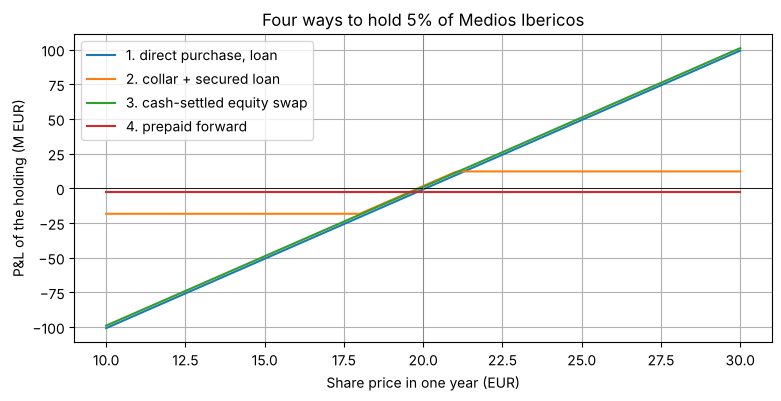

In [5]:
ST = np.linspace(10, 30, 201)
for name in strategies:
    plt.plot(ST, [pnl(name, s) / 1e6 for s in ST], label=name)
plt.axhline(0, color="k", lw=0.6); plt.axvline(S0, color="grey", lw=0.6)
plt.xlabel("Share price in one year (EUR)"); plt.ylabel("P&L of the holding (M EUR)"); plt.legend()
plt.title("Four ways to hold 5% of Medios Ibericos"); plt.show()

**Lectura.**

- **Compra directa:** vota y se queda con todo el riesgo; si se financia entera, el préstamo sin garantía específica
  es caro y consume la capacidad de deuda del holding.
- **Collar financiado:** vota, acota la pérdida al 10 % más la financiación y renuncia a las subidas por encima de la
  call. Como el suelo garantiza el préstamo, el banco presta casi el 90 % del valor más barato. Es la estructura
  clásica para financiar participaciones (Schofield 10.6.2 y 11.2.4).
- **Equity swap en efectivo:** casi no necesita caja y da toda la exposición económica, pero **no da voto**: no
  sirve para el objetivo de influir. Útil para tomar posición antes de comprar, con cuidado con la comunicación.
- **Forward prepagado:** vota, sin riesgo de precio y con solo la comisión como coste de caja. Es la solución que
  eligió AILTD. Contrapartidas: riesgo de crédito con el banco, préstamo de títulos disponible y una estructura
  que el supervisor mirará como posible *empty voting* (voto sin interés económico).

## 4. Límites de comunicación de participaciones (España, octubre de 2026)

- **Umbrales:** se comunica al alcanzar, superar o bajar del 3 %, 5 %, 10 %, 15 %, 20 %, 25 %, 30 % y siguientes de
  los derechos de voto (RD 1362/2007, art. 23.1).
- **Instrumentos financieros:** los mismos umbrales se aplican a instrumentos con efecto económico similar a tener
  las acciones, se liquiden con entrega o en efectivo (equity swaps, CFD, opciones), y a la suma de acciones e
  instrumentos (arts. 28 y 28 bis). Los liquidados en efectivo se computan ajustados por delta (Reglamento
  Delegado (UE) 2015/761). El equity swap del caso cuenta para el 5 % aunque no dé voto.
- **Plazo:** cuatro días hábiles bursátiles desde que se conoce el hecho (procedimiento P08 de la CNMV).
- **Cambios de 2026:** el RD 813/2026 (BOE del 8 de octubre, en vigor el 28 de octubre de 2026) sube del 1 % al 3 %
  el umbral de comunicación durante una OPA y fija umbrales del 3 %, 5 % y 10 % para la autocartera del emisor.
- **Más allá:** al llegar al 30 % de los derechos de voto hay que lanzar una OPA obligatoria (RD 1066/2007), y la
  información privilegiada (MAR) limita cuándo se puede operar. Antes de ejecutar, cumplimiento normativo y
  asesoría legal deben validar la estructura.

## 5. Comprobaciones

In [6]:
assert abs(trs_pnl(S0, S0 * (1 + breakeven), 0.0, 1.0, 0.0, 0.0) / S0 - breakeven) < 1e-12
assert probs[0] < probs[1] < probs[2]
assert 0 < cs < call70
assert abs(bs_spot(S0, Kc, 1.0, r1, q_s, vol_call) - bs_spot(S0, Kp, 1.0, r1, q_s, vol_put, call=False)) < 1e-9
assert summary.loc["2. collar + secured loan", "P&L if share -30% (M EUR)"] > summary.loc["1. direct purchase, loan", "P&L if share -30% (M EUR)"]
assert summary.loc["4. prepaid forward", "cash needed today (M EUR)"] < summary.loc["3. cash-settled equity swap", "cash needed today (M EUR)"]
assert summary.loc["3. cash-settled equity swap", "votes"] == "no"
print("All checks passed")

All checks passed


## Ejercicios

1. **Básico.** ¿Cuánto tiene que subir la acción para que el receptor del equity swap no pierda si el diferencial
   fuera del 1,2 % en vez del 0,6 %?
2. **Intermedio.** Con un put al 85 %, ¿qué strike tiene la call del collar de coste cero y cuánto presta el banco?
3. **Avanzado.** En el caso del convertible, ¿a qué precio de la acción vuelve a ser la dilución con el call spread la
   mitad de la dilución sin cobertura?

## Soluciones

In [7]:
print(f"spread 1.2%: break-even rise {(rate(1.0) + 0.012) - q_div:.2%} (vs {breakeven:.2%} at 0.6%)")

spread 1.2%: break-even rise 0.09% (vs -0.51% at 0.6%)


In [8]:
Kp85 = 0.85 * S0
Kc85 = zero_cost_call_strike(S0, 1.0, r1, q_s, 0.33, 0.28, Kp85)
print(f"put 85% ({Kp85:.2f} EUR): call at {Kc85:.2f} EUR ({Kc85 / S0:.1%}); loan {collar_max_loan(Kp85, 1.0, r1, 0.006) * N_sh / 1e6:.1f} M EUR")

put 85% (17.00 EUR): call at 22.16 EUR (110.8%); loan 165.8 M EUR


In [9]:
print("With the call spread the company receives (min(S, 100) - 70) per share from the bank and must issue shares")
print(f"for the rest: new shares = 5M x (S - 100) / S. They equal half of 5M when S = 200 EUR, {200 / S_m:.1f} times today's price.")

With the call spread the company receives (min(S, 100) - 70) per share from the bank and must issue shares
for the rest: new shares = 5M x (S - 100) / S. They equal half of 5M when S = 200 EUR, 3.2 times today's price.
